# plotnine ❤️ polars, through narwhals

This notebook demonstrates an experimental version of
[plotnine](https://plotnine.org) in which
[pandas](https://pandas.pydata.org) is no longer required.
Internally, plotnine uses [narwhals](https://narwhals-dev.github.io/narwhals/),
so it works natively with [polars](https://pola.rs) dataframes,
and with the other dataframe libraries that narwhals supports.

- polars dataframes are **not** converted to pandas;
- plotnine does **not** import pandas;
- aesthetics can be **narwhals expressions**, and string
  expressions keep working;
- polars `Enum` columns are treated as **ordered** categoricals;
- densities, violins and linear smooths no longer need statsmodels.

The code is in the `narwhals-optional-pandas` branch of
[my fork of plotnine](https://github.com/jeroenjanssens/plotnine/tree/narwhals-optional-pandas)
and the `optional-pandas` branch of
[my fork of mizani](https://github.com/jeroenjanssens/mizani/tree/optional-pandas).

In [ ]:
import sys
from pathlib import Path

import marimo as mo
import narwhals as nw
import numpy as np
import polars as pl

import plotnine
from plotnine import (
    aes,
    after_stat,
    annotate,
    coord_flip,
    facet_wrap,
    geom_bar,
    geom_boxplot,
    geom_density,
    geom_density_2d,
    geom_histogram,
    geom_point,
    geom_smooth,
    geom_violin,
    ggplot,
    I,
    labs,
    scale_fill_brewer,
    theme,
    theme_minimal,
)

## The data

We read two of the datasets that ship with plotnine directly with
polars. For the `diamonds` data, we turn `cut`, `color` and
`clarity` into polars `Enum`s: their categories have a meaningful
order.

In [ ]:
data_dir = Path(plotnine.__file__).parent / "data"

mpg = pl.read_csv(data_dir / "mpg.csv")

diamonds = pl.read_csv(data_dir / "diamonds.csv").with_columns(
    cut=pl.col("cut").cast(
        pl.Enum(["Fair", "Good", "Very Good", "Premium", "Ideal"])
    ),
    color=pl.col("color").cast(pl.Enum(list("DEFGHIJ"))),
    clarity=pl.col("clarity").cast(
        pl.Enum(["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"])
    ),
)
mpg.head()

manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
str,str,f64,i64,i64,str,str,i64,i64,str,str
"""audi""","""a4""",1.8,1999,4,"""auto(l5)""","""f""",18,29,"""p""","""compact"""
"""audi""","""a4""",1.8,1999,4,"""manual(m5)""","""f""",21,29,"""p""","""compact"""
"""audi""","""a4""",2.0,2008,4,"""manual(m6)""","""f""",20,31,"""p""","""compact"""
"""audi""","""a4""",2.0,2008,4,"""auto(av)""","""f""",21,30,"""p""","""compact"""
"""audi""","""a4""",2.8,1999,6,"""auto(l5)""","""f""",16,26,"""p""","""compact"""


## 1. Narwhals expressions and string expressions

An aesthetic can be a column name, a narwhals expression, or a
string expression. Here we convert miles per gallon to kilometers
per liter with a narwhals expression, and use the string
expression `"factor(cyl)"` to treat the number of cylinders as a
categorical variable.

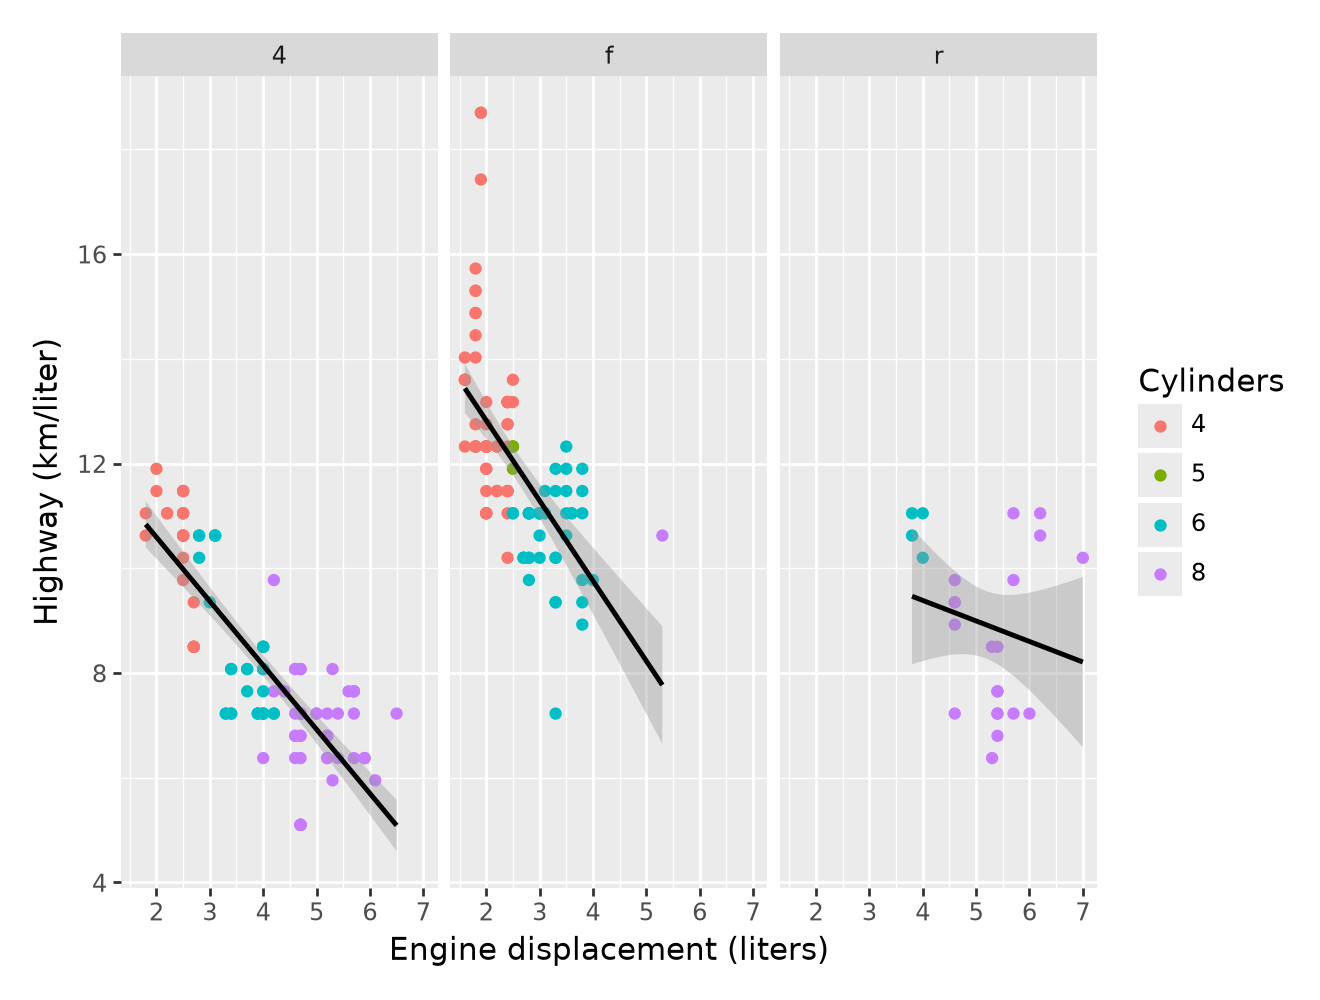

In [ ]:
km_per_liter = nw.col("hwy") * 0.425

(
    ggplot(mpg, aes("displ", km_per_liter, color="factor(cyl)"))
    + geom_point()
    + geom_smooth(aes(group=1), method="lm", color="black")
    + facet_wrap("drv")
    + labs(
        x="Engine displacement (liters)",
        y="Highway (km/liter)",
        color="Cylinders",
    )
).draw()

String expressions are evaluated as narwhals expressions where
possible, so numpy functions work on polars columns:

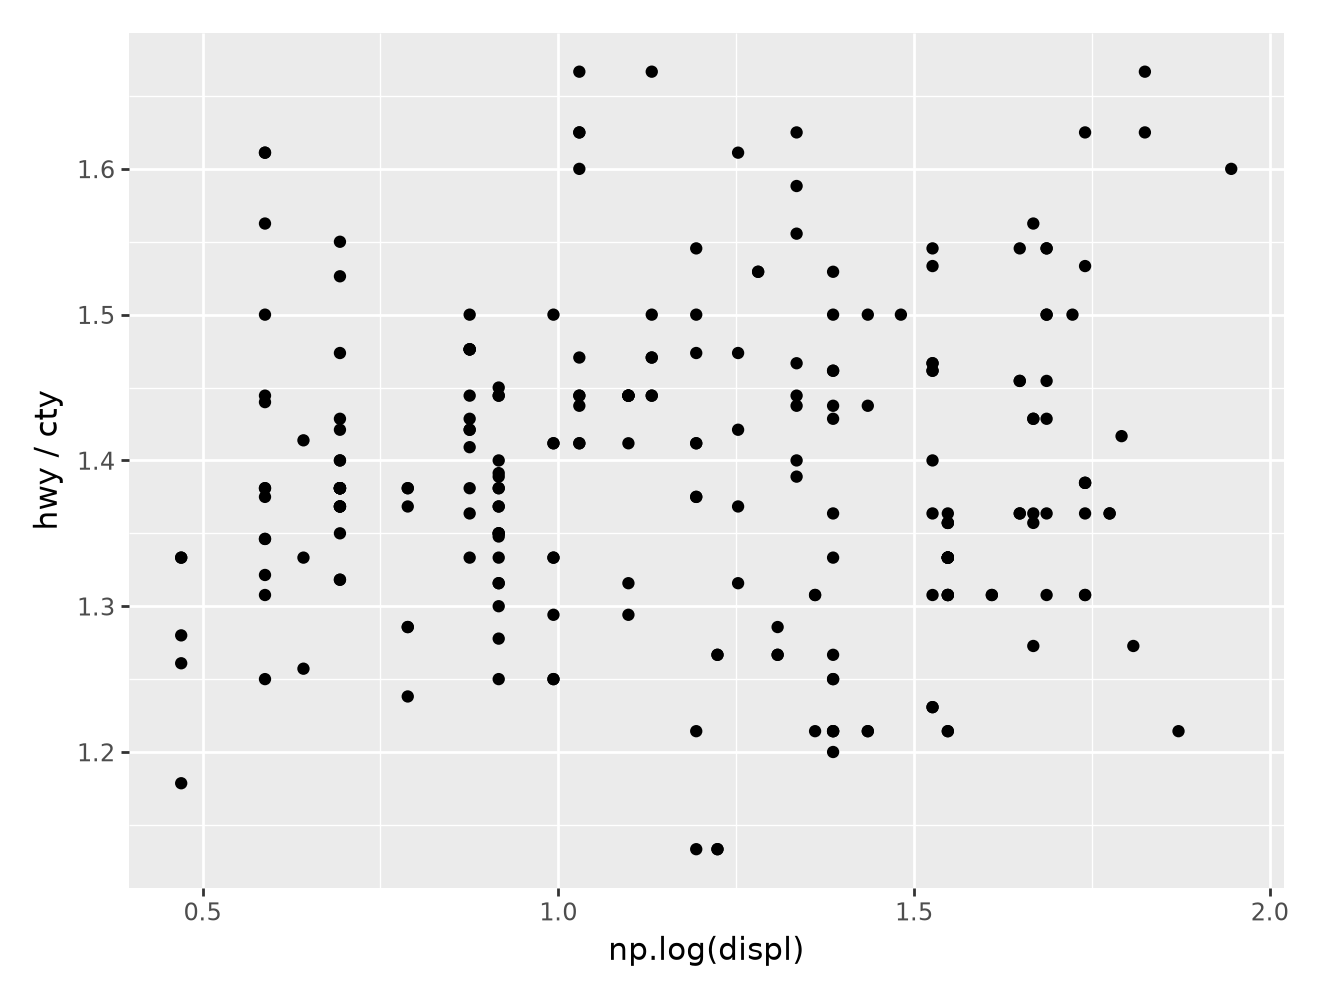

In [ ]:
# np must be known where ggplot() is called
(ggplot(mpg, aes("np.log(displ)", "hwy / cty")) + geom_point()).draw()

## 2. Ordered and unordered categoricals

A polars `Enum` has its categories in a meaningful order, so
plotnine treats it as an *ordered* categorical (like a pandas
categorical with `ordered=True`) and uses an ordinal colour scale
(viridis). A polars `Categorical` is unordered and gets a
qualitative colour scale (hue).

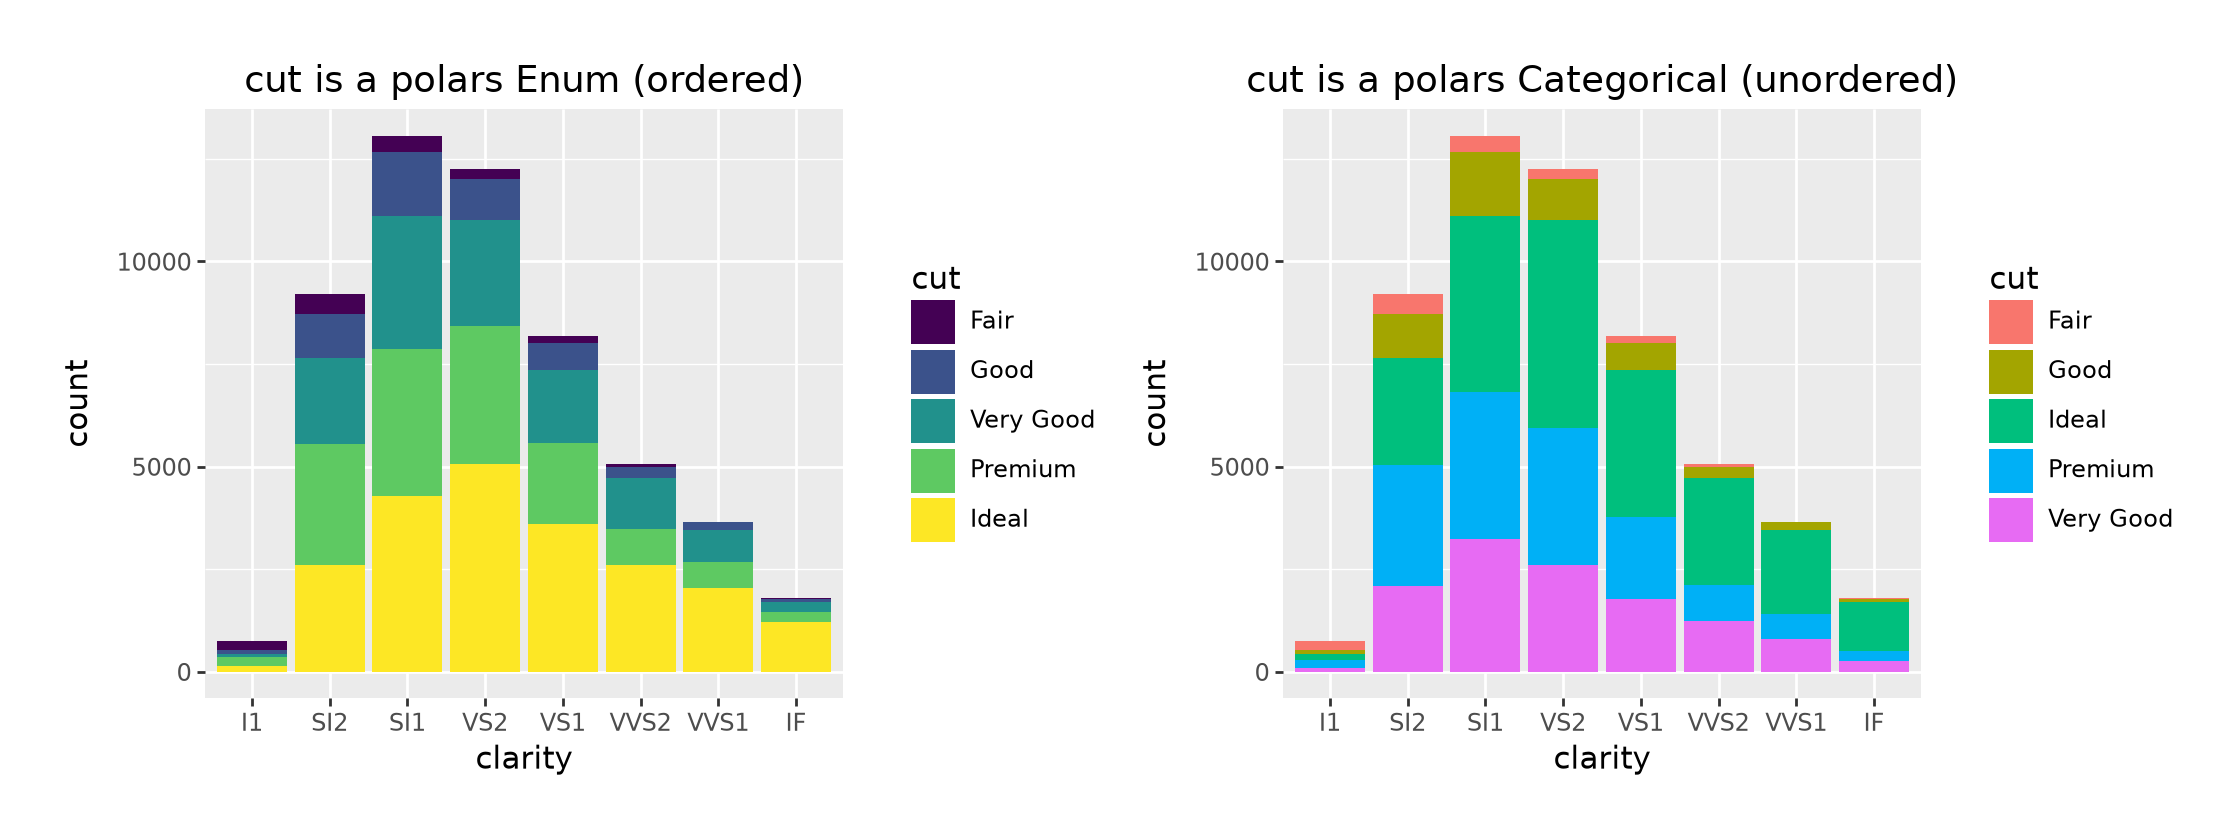

In [ ]:
as_enum = (
    ggplot(diamonds, aes("clarity", fill="cut"))
    + geom_bar()
    + labs(title="cut is a polars Enum (ordered)")
)

as_categorical = (
    ggplot(
        diamonds.with_columns(pl.col("cut").cast(pl.String).cast(pl.Categorical)),
        aes("clarity", fill="cut"),
    )
    + geom_bar()
    + labs(title="cut is a polars Categorical (unordered)")
)

((as_enum | as_categorical) & theme(figure_size=(11, 4))).draw()

## 3. Statistics

These statistics are computed with numpy and scipy. Kernel
densities and linear models used to require statsmodels (which
requires pandas).

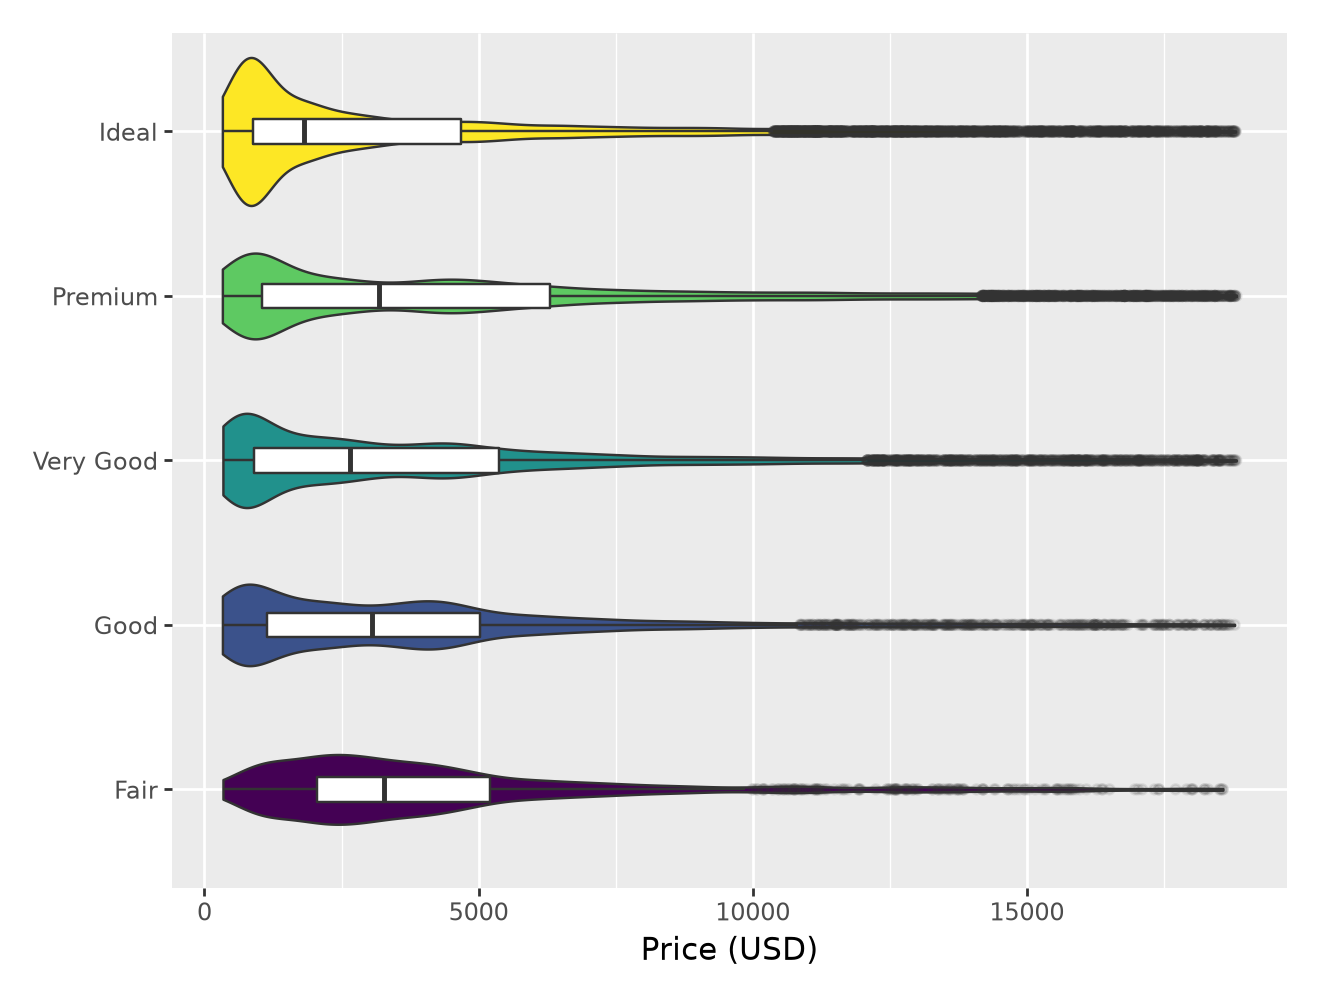

In [ ]:
(
    ggplot(diamonds, aes("cut", "price", fill="cut"))
    + geom_violin(show_legend=False)
    + geom_boxplot(width=0.15, fill="white", outlier_alpha=0.1)
    + coord_flip()
    + labs(x="", y="Price (USD)")
).draw()

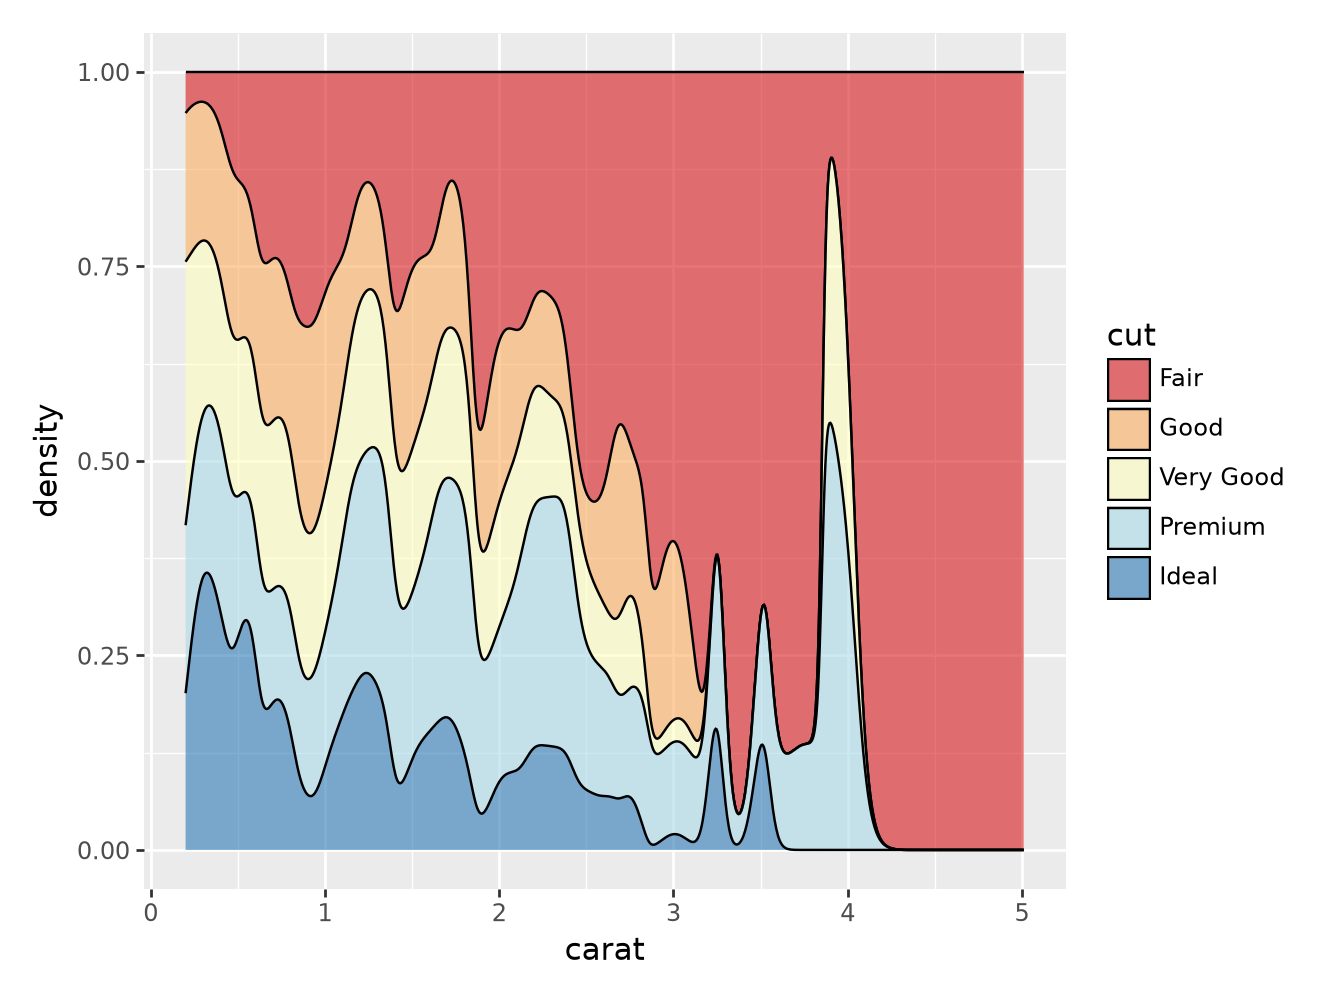

In [ ]:
(
    ggplot(diamonds, aes("carat", fill="cut"))
    + geom_density(alpha=0.6, position="fill")
    + scale_fill_brewer(palette="RdYlBu", type="div")
).draw()

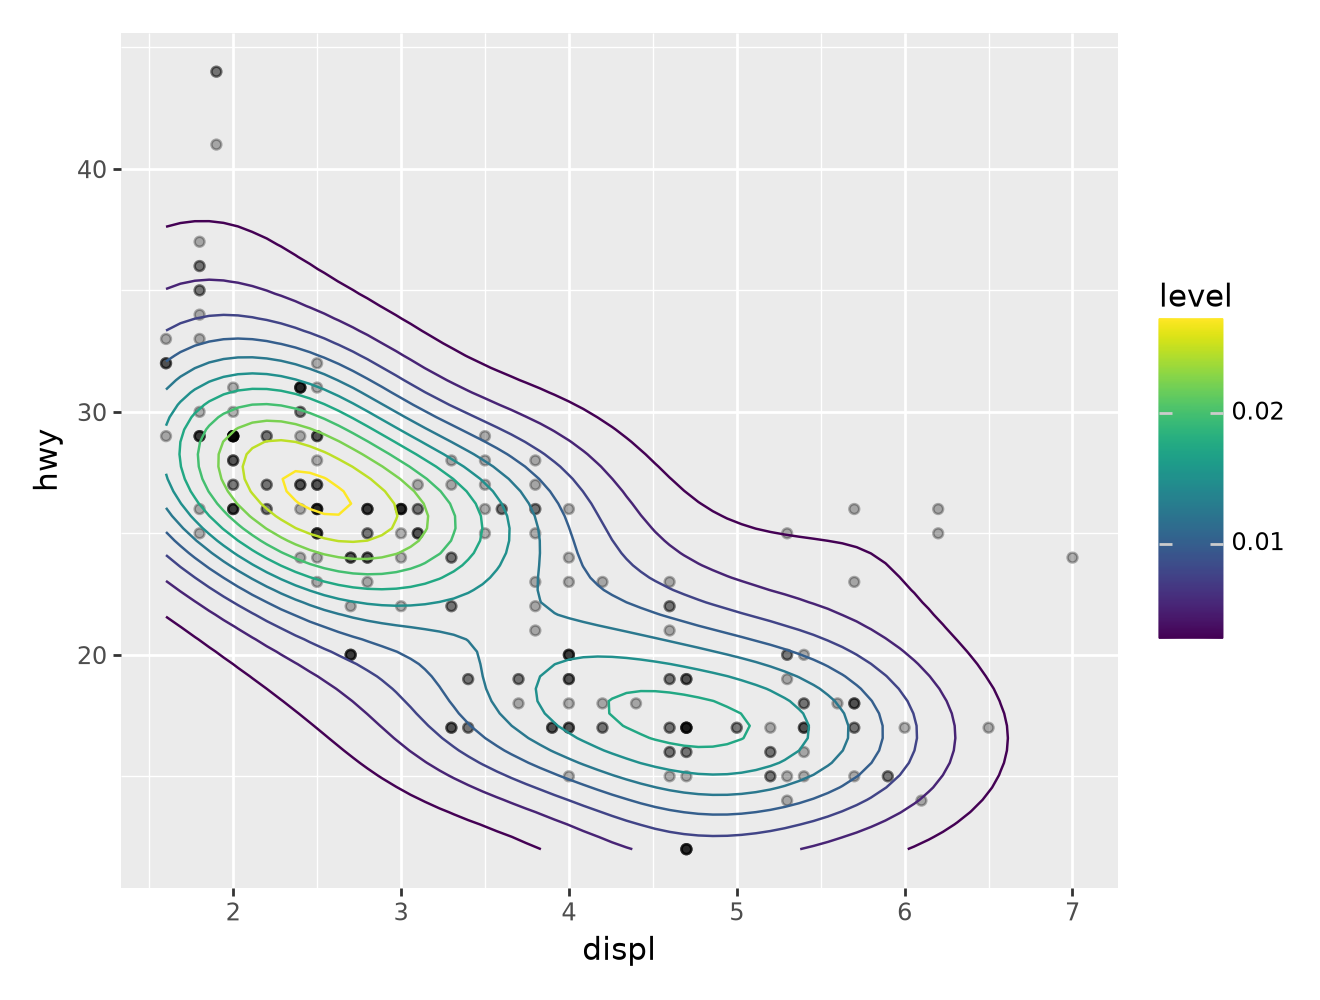

In [ ]:
(
    ggplot(mpg, aes("displ", "hwy"))
    + geom_point(alpha=0.3)
    + geom_density_2d(aes(color=after_stat("level")))
).draw()

## 4. Other dataframe libraries

Thanks to narwhals, a [PyArrow](https://arrow.apache.org/docs/python/)
table works too. The layer data that plotnine computes stays a
PyArrow table.

type of the layer data: Table


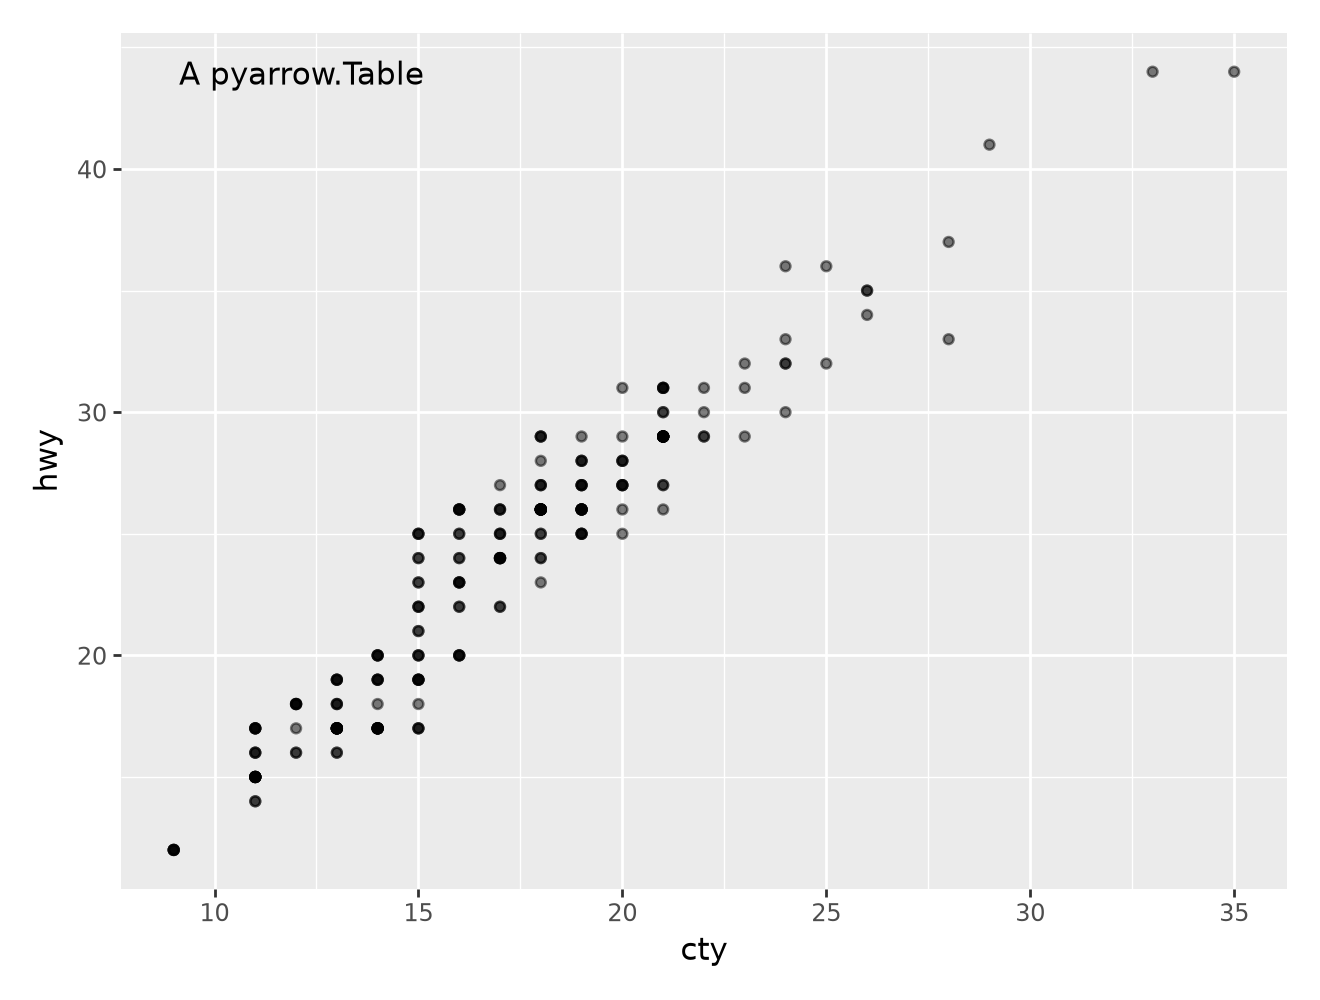

In [ ]:
table = mpg.to_arrow()
p = (
    ggplot(table, aes("cty", "hwy"))
    + geom_point(alpha=0.5)
    + annotate(
        "text", x=I(0.05), y=I(0.95), label="A pyarrow.Table", ha="left"
    )
)
print("type of the layer data:", type(p.layer_data()).__name__)
p.draw()

## 5. No pandas

The claim: plotnine does not need pandas. Here we draw a plot in a
separate Python process in which pandas cannot be imported at all.
(We use a separate process because the notebook environment itself
may import pandas.)

In [ ]:
import subprocess
import textwrap

code = textwrap.dedent(
    """
    import sys

    class BlockPandas:
        def find_spec(self, name, path=None, target=None):
            if name == "pandas" or name.startswith("pandas."):
                raise ModuleNotFoundError("pandas is blocked")

    sys.meta_path.insert(0, BlockPandas())

    from io import BytesIO
    from pathlib import Path

    import polars as pl
    import plotnine
    from plotnine import aes, geom_density, geom_point, geom_smooth, ggplot

    mpg = pl.read_csv(Path(plotnine.__file__).parent / "data" / "mpg.csv")
    (
        ggplot(mpg, aes("displ", "hwy", color="factor(cyl)"))
        + geom_point()
        + geom_smooth(method="lm")
    ).save(BytesIO(), format="png", verbose=False)
    (ggplot(mpg, aes("hwy")) + geom_density()).save(
        BytesIO(), format="png", verbose=False
    )
    print("Drew the plots. pandas imported:", "pandas" in sys.modules)
    """
)
result = subprocess.run(
    [sys.executable, "-c", code], capture_output=True, text=True
)
mo.md(
    f"""
    **Exit code:** `{result.returncode}`

    **Output:** `{result.stdout.strip() or result.stderr.strip()[-500:]}`
    """
)

**Exit code:** `0`

**Output:** `Drew the plots. pandas imported: False`

In [ ]:
import importlib.metadata as metadata

def version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

packages = ["plotnine", "mizani", "narwhals", "polars", "pyarrow", "pandas"]
mo.md(
    "### Package versions\n\n"
    + "\n".join(f"- **{p}**: `{version(p)}`" for p in packages)
    + f"\n\n`'pandas' in sys.modules`: `{'pandas' in sys.modules}`"
)

### Package versions

- **plotnine**: `0.16.0+narwhals`
- **mizani**: `0.14.7+optionalpandas`
- **narwhals**: `2.28.0`
- **polars**: `2.1.0`
- **pyarrow**: `26.0.0`
- **pandas**: `not installed`

`'pandas' in sys.modules`: `False`